# Monte Carlo tolerancing: an air-spaced achromat and Caldwell's KrF lens

A lens design is a list of numbers, and no lens is built exactly to them. Every
radius is polished to within a few fringes of a test plate, every centre
thickness to within some tens of micrometres, every glass melt has its own
index and Abbe number, every element sits a little off the axis in its mount,
and the lens and the detector sit a little off their nominal axial positions.
Tolerancing answers three questions:

1. **Sensitivity**: which errors matter, and how much does each one cost?
2. **Yield**: what fraction of the built lenses meets the specification?
3. **Compensation**: what can be adjusted at assembly (the focus, the
   position of an element) to win back what the errors took?

There are three ways to answer them, which this notebook uses side by side:

- the **sensitivity table**: one error at a time at its limit, with the
  compensators adjusted (the "inverse sensitivity" listing of lens design
  programs),
- **Monte Carlo**: many random lenses with all errors at once, each one
  traced and compensated like a real lens on the assembly bench,
- the **linear model**: the performance (ray errors or the OPD over the pupil)
  linearized in all errors, with the merit as the exact quadratic form of the
  linear model. Its mean square is the classical root-sum-square (RSS)
  estimate, and it evaluates a hundred thousand lenses in a second.

`pyoptics.tolerancing` provides the tolerances (`Power` in fringes,
`Radius`, `Thickness` for centre thicknesses and air spaces, `AxialShift` of an
element between fixed neighbours, `ImagePlane`, `Index`, `Abbe`, `Decenter`),
the performance vectors (`SpotErrors`, `WavefrontErrors`), compensators (any
`lens_optimization.Variable`, e.g. the image distance for the focus, `AirSpace`
for an axial manipulator, `tolerancing.LateralShift` for a lateral one) and
`ToleranceAnalysis` with `sensitivities()`, `monte_carlo()` and
`linear_model()`.

**Part 1** is an air-spaced achromat, f = 100 mm at F/5, small and fast enough for
thousands of fully traced lenses. Its merit is the polychromatic RMS spot
radius plus the axial colour.

1. The lens
2. The tolerances
3. Sensitivities, one error at a time
4. Monte Carlo: yield
5. Axial positioning: fixed or adjusted focus
6. The linear model against the full traces
7. Tightening the budget, and the cemented doublet

**Part 2** is Caldwell's all fused silica KrF lithography lens (notebooks 19,
43 and 44): 21 elements, 147 tolerances, RMS wavefront error over the field.

8. Sensitivities of 147 tolerances
9. The linear model against full Monte Carlo runs, and where it breaks
10. Manipulators: what adjustable elements win back

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import raytrace as rt
from pyoptics import lens_optimization as lo
from pyoptics import tolerancing as tol
from pyoptics.materials import LAMBDA_F, LAMBDA_C, LAMBDA_d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()

WL_F, WL_d, WL_C = LAMBDA_F*1e-6, LAMBDA_d*1e-6, LAMBDA_C*1e-6  # mm
BK7, F2 = lo.GLASSES["N-BK7"], lo.GLASSES["N-F2"]
BLUE, ORANGE, GREEN, YELLOW, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#d03b3b", "#888888"
GROUP_COLOR = {"radius": BLUE, "thickness": GREEN, "axial position": YELLOW, "index": RED,
               "Abbe number": "#8a5cc2", "decenter": ORANGE}

## 1. The lens

A Fraunhofer type achromat: a biconvex N-BK7 crown, a thin air gap and a
negative N-F2 flint meniscus, f = 100 mm, F/5 (entrance pupil 20 mm, stop at
the first surface), field ±1°. The thin lens powers of crown and flint come
from the achromat condition, then `DampedLeastSquares` (notebook 58) bends
the four surfaces for the smallest polychromatic ray errors at F, d and C,
with the focal length and the paraxial F - C focus difference held as
constraints and the image plane in the paraxial focus. The air gap gives two
more curvatures than a cemented doublet, enough to correct spherical aberration
and coma together: the classical reason for air-spaced objectives.

In [2]:
def thin_achromat(f=100.0, crown=BK7, flint=F2):
    (n1, V1), (n2, V2) = crown, flint
    return V1/(V1 - V2)/f/(n1 - 1), -V2/(V1 - V2)/f/(n2 - 1)  # c1 - c2 of crown and flint


def design(surfaces, efl=100.0, epd=20.0, field_deg=1.0):
    s0 = rt.System(surfaces, 0, WL_d, field_angle=np.deg2rad(field_deg),
                   entrance_pupil_radius=epd/2).at_paraxial_focus()
    cons = [lo.Constraint(lo.paraxial_value("efl"), efl, efl, tolerance=1e-3, name="efl"),
            lo.Constraint(lambda s: lo.focal_shift(WL_F, WL_C, tolerance=1.0)(s)[0], 0.0, 0.0,
                          tolerance=1e-4, name="F - C focus")]
    ops = [lo.polychromatic_ray_errors([WL_F, WL_d, WL_C], fields=(0.0, 0.7, 1.0), tolerance=0.002)]
    opt = lo.DampedLeastSquares(s0, lo.curvatures(s0), ops, cons, solves=[lo.solve_paraxial_focus()])
    return opt.run(max_iterations=40).system


k1, k2 = thin_achromat()
c1 = k1/2
c3 = -c1 - 0.002
SD = 11.5
achromat = design([rt.Surface(1/c1, 6.0, material=BK7, semi_diameter=SD),
                   rt.Surface(-1/c1, 0.5, n_after=1.0, semi_diameter=SD),
                   rt.Surface(1/c3, 3.0, material=F2, semi_diameter=SD),
                   rt.Surface(1/(c3 - k2), 95.0, n_after=1.0, semi_diameter=SD)])


def axial_colour(s):
    # paraxial F - C focus difference in um
    return 1e3*lo.focal_shift(WL_F, WL_C, tolerance=1.0)(s)[0]


p = achromat.paraxial()
print(achromat)
print(f"efl {p.efl:.3f} mm, F/{p.f_number:.2f}, axial colour F - C {axial_colour(achromat):+.3f} um, "
      f"secondary spectrum d - F {1e3*lo.focal_shift(WL_d, WL_F, tolerance=1.0)(achromat)[0]:+.1f} um")
DOF = 2*WL_d*p.f_number**2*1e3
print(f"depth of focus +-2 lambda N^2 = +-{DOF:.0f} um, Airy radius {1.22*WL_d*p.f_number*1e3:.1f} um")

System(wavelength=0.0005875618, stop_index=0, object_distance=inf, max_field=0.017453292519943295)
   0* Surface(R=47.66629313505125, thickness=6.0, n_after=None, material=(1.5168, 64.17), conic=0.0, aspheric=(), semi_diameter=10.0) n'=1.516800
   1  Surface(R=-38.25143563761869, thickness=0.5, n_after=1.0, material=None, conic=0.0, aspheric=(), semi_diameter=11.5) n'=1.000000
   2  Surface(R=-37.72241597474812, thickness=3.0, n_after=None, material=(1.62005, 36.43), conic=0.0, aspheric=(), semi_diameter=11.5) n'=1.620050
   3  Surface(R=-326.95455579067635, thickness=92.9972846073623, n_after=1.0, material=None, conic=0.0, aspheric=(), semi_diameter=11.5) n'=1.000000
efl 100.000 mm, F/5.00, axial colour F - C -0.002 um, secondary spectrum d - F +0.3 um
depth of focus +-2 lambda N^2 = +-29 um, Airy radius 3.6 um


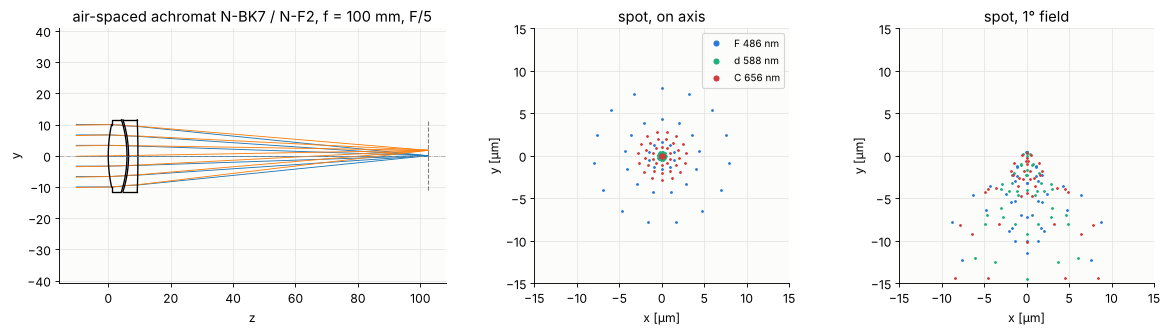

In [3]:
FIELDS = (0.0, 1.0, -1.0, (1.0, 0.0))   # field points of the spot merit: centre, +-y edge, x edge
spot = tol.SpotErrors(FIELDS, wavelengths=[WL_F, WL_d, WL_C])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.3, 1, 1]})
achromat.draw(axes[0], fields=[0.0, achromat.max_field], n_rays=7)
axes[0].set_title("air-spaced achromat N-BK7 / N-F2, f = 100 mm, F/5")
for ax, f, title in [(axes[1], 0.0, "on axis"), (axes[2], achromat.max_field, "1° field")]:
    for w, col, lab in [(WL_F, BLUE, "F 486 nm"), (WL_d, GREEN, "d 588 nm"), (WL_C, RED, "C 656 nm")]:
        sw = achromat.with_wavelength(w)
        I = sw._image_hits(sw.trace(sw.rays(f, spot.px, spot.py), clip=False))[0]
        Id = achromat._image_hits(achromat.trace_pupil(f, 0.0, 0.0))[0][0]
        ax.plot((I[:, 0] - Id[0])*1e3, (I[:, 1] - Id[1])*1e3, ".", ms=3, color=col, label=lab)
    ax.set_aspect("equal")
    ax.set_xlim(-15, 15)
    ax.set_ylim(-15, 15)
    ax.set_xlabel("x [µm]")
    ax.set_ylabel("y [µm]")
    ax.set_title(f"spot, {title}")
axes[1].legend(fontsize=9, markerscale=3)
fig.tight_layout()

The spots are a few micrometres across, about the size of the Airy disk
(3.6 µm radius), with the secondary spectrum of N-BK7/N-F2 (F and C meet, d
focuses about 50 µm short of them) and a little coma and astigmatism at
the edge of the field.

## 2. The tolerances

Typical commercial values from an optics shop and a glass catalogue:

| tolerance | limit | class |
|---|---|---|
| power of every surface | ±3 fringes (HeNe, over the clear aperture) | `Power` |
| centre thicknesses | ±50 µm | `Thickness` |
| air gap between crown and flint (despace) | ±30 µm | `Thickness` |
| axial position of the doublet in the barrel | ±50 µm | `AxialShift` |
| refractive index n_d | ±5·10⁻⁴ | `Index` |
| Abbe number V_d | ±0.8 % | `Abbe` |
| decentre of each element, x and y | ±20 µm | `Decenter` |
| image plane (setting the focus) | ±20 µm, after focusing | `ImagePlane` |

A power error of N fringes is a sag difference of Nλ/2 against the test
plate at the rim h of the surface, i.e. a curvature error
$\Delta c = N\lambda/h^2$; for the 55 mm radius of the crown at h = 11.5 mm, 3
fringes are 44 µm of radius.

Each error is drawn from a Gaussian with $\sigma$ = limit/2, cut at the limit
(the shop rejects what is out of tolerance). The two other distributions of
`Tolerance` are uniform (a process that drifts across the range) and the end
points (the worst case of each).

The **compensator** is the focus: the image distance is adjusted for the
smallest spot, as on the assembly bench. The image plane error is then the
accuracy of setting (and holding) the focus, applied after the adjustment.

In [4]:
ELEMENTS = [(0, 1), (2, 3)]
tolerances = tol.element_tolerances(achromat, ELEMENTS, fringes=3.0, thickness=0.05, index=5e-4,
                                    abbe=0.008, decenter=0.02)
tolerances += [tol.Thickness(1, 0.03, name="air gap"),
               tol.AxialShift(0, 3, 0.05, name="lens z"),
               tol.ImagePlane(0.02)]
focus = [lo.Thickness(-1)]
metrics = {"axial colour": axial_colour}
ana = tol.ToleranceAnalysis(achromat, tolerances, spot, focus, metrics)
nominal = ana.nominal_rms()*1e3
print(f"{len(tolerances)} tolerances:", ", ".join(t.name for t in tolerances))
print("nominal RMS spot radius, refocused [um]:", np.round(nominal, 2), f"(worst {nominal.max():.2f})")

17 tolerances: R1, R2, R3, R4, t1, t3, n1, n3, V1, V3, dx1-2, dy1-2, dx3-4, dy3-4, air gap, lens z, z_img
nominal RMS spot radius, refocused [um]: [3.57 5.19 5.19 5.19] (worst 5.19)


## 3. Sensitivities, one error at a time

Every tolerance at +limit and -limit, the focus readjusted, all others
nominal. The left panel shows the RMS spot radius of the worst field, the
right panel the change of the axial colour. Below them is each tolerance's
share in the increase of the mean square spot radius (all fields together)
in the linear model, $\sigma_k^2\,|\mathbf B_k|^2$: the variance budget.

RSS estimate of the RMS spot (all fields): 5.48 um, nominal 4.83 um
standard deviation of the axial colour (linear): 18.1 um


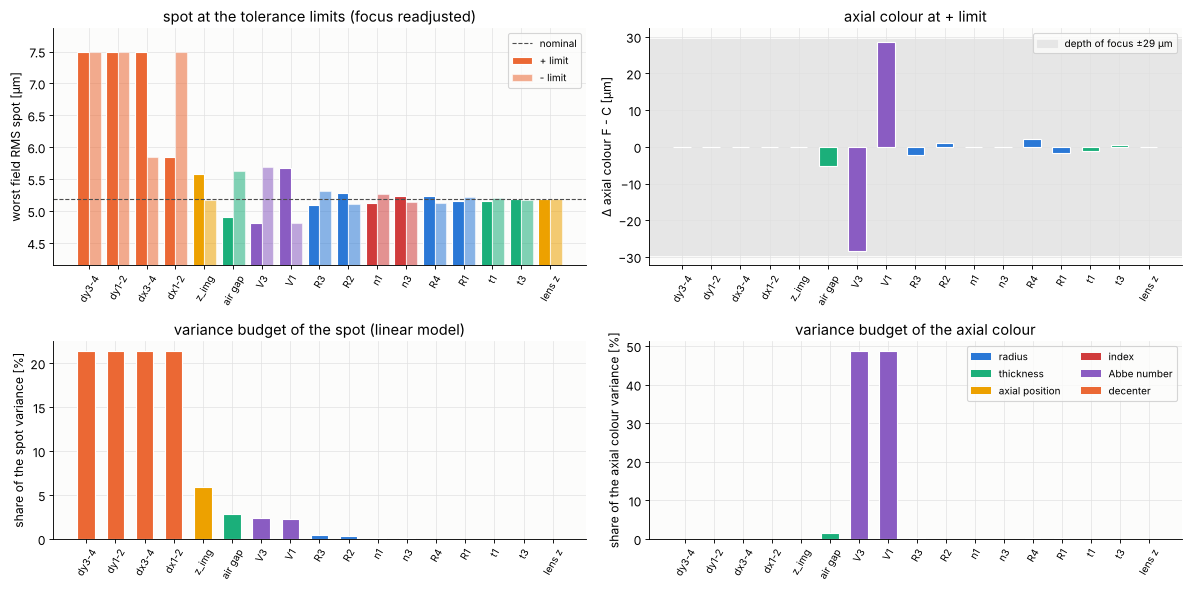

In [5]:
sens, model = ana.sensitivities()
order = np.argsort(-sens.share)
names = [sens.names[k] for k in order]
cols = [GROUP_COLOR[sens.groups[k]] for k in order]
x = np.arange(len(order))

fig, axes = plt.subplots(2, 2, figsize=(15, 7.5), gridspec_kw={"height_ratios": [1.2, 1]})
ax = axes[0, 0]
ax.bar(x - 0.2, sens.plus[order].max(1)*1e3, 0.4, color=cols, edgecolor="white", label="+ limit")
ax.bar(x + 0.2, sens.minus[order].max(1)*1e3, 0.4, color=cols, alpha=0.55, edgecolor="white",
       label="- limit")
ax.axhline(nominal.max(), color="0.3", lw=1, ls="--", label="nominal")
ax.set_ylim(nominal.max()*0.8, None)
ax.set_xticks(x, names, rotation=60, fontsize=9)
ax.set_ylabel("worst field RMS spot [µm]")
ax.set_title("spot at the tolerance limits (focus readjusted)")
ax.legend(fontsize=9)
ax = axes[0, 1]
dcol = sens.metrics_plus["axial colour"][order] - ana.m0["axial colour"]
ax.bar(x, dcol, 0.6, color=cols, edgecolor="white")
ax.axhspan(-DOF, DOF, color="0.9", zorder=0, label=f"depth of focus ±{DOF:.0f} µm")
ax.set_xticks(x, names, rotation=60, fontsize=9)
ax.set_ylabel("Δ axial colour F - C [µm]")
ax.set_title("axial colour at + limit")
ax.legend(fontsize=9)
ax = axes[1, 0]
ax.bar(x, 100*sens.share[order], 0.6, color=cols, edgecolor="white")
ax.set_xticks(x, names, rotation=60, fontsize=9)
ax.set_ylabel("share of the spot variance [%]")
ax.set_title("variance budget of the spot (linear model)")
ax = axes[1, 1]
G = model.G[0]
var_col = (sens.sigmas*G)**2
ax.bar(x, 100*var_col[order]/var_col.sum(), 0.6, color=cols, edgecolor="white")
ax.set_xticks(x, names, rotation=60, fontsize=9)
ax.set_ylabel("share of the axial colour variance [%]")
ax.set_title("variance budget of the axial colour")
for g, c in GROUP_COLOR.items():
    axes[1, 1].bar([0], [0], color=c, label=g)
axes[1, 1].legend(fontsize=9, ncol=2)
fig.tight_layout()
print(f"RSS estimate of the RMS spot (all fields): {1e3*np.sqrt(model.mean_square()):.2f} um, "
      f"nominal {1e3*np.sqrt(np.mean(nominal**2)/1e6):.2f} um")
print(f"standard deviation of the axial colour (linear): {np.sqrt(var_col.sum()):.1f} um")

The two merits are spoiled by different tolerances:

- **The spot is a matter of centring.** The four decentres together take
  85 % of the budget: a 20 µm decentre of either element adds coma on axis
  and makes the spot grow by half. The two strongly curved inner
  surfaces facing each other across the thin air gap (radii of about −38 mm)
  carry large, opposite spherical aberration and coma contributions. Shifting one
  against the other upsets the balance (notebook 44 shows the same mechanism
  in the KrF lens). The air gap itself (the **despace**) comes next: it
  sets how much the steep inner surfaces cancel, i.e. the spherical
  aberration, and the focus cannot undo that.
- **The axial colour is a matter of glass.** It hardly depends on the
  geometry. The Abbe number tolerance of ±0.8 % of the crown or the flint
  alone moves the F - C focus difference by about 28 µm, a full depth of
  focus. The thin lens achromat explains this: the crown and the flint
  each have about 2.3 times the power of the doublet, and their colours
  cancel. A relative error ΔV/V of one of them leaves
  $\Delta(F - C) \approx f\,(\varphi_1/\varphi)\,\Delta V/V/V_1 \approx 100 \cdot 2.3 \cdot 0.008/64$ mm, about 29 µm.
- **Axial positions** of the lens in the barrel and the radii are
  harmless here: with the object at infinity, moving the doublet along the
  axis just moves the focus, and the focus is readjusted. What is left is
  the accuracy of the focus setting itself (`z_img`), about 6 % of the
  budget. Section 5 removes the adjustment.

## 4. Monte Carlo: yield

A thousand random lenses, every error drawn from its distribution, each
lens traced at F, d and C over the four field points, refocused and
evaluated. The specification: worst field RMS spot radius at most 7 µm,
and an axial colour within the depth of focus, |F - C| ≤ 30 µm.

In [6]:
SPEC_SPOT, SPEC_COL = 7.0, 30.0
t0 = time.time()
mc = ana.monte_carlo(1000, seed=1)
t_mc = time.time() - t0
worst = mc.rms.max(1)*1e3
col = mc.metrics["axial colour"]
ok_spot = worst <= SPEC_SPOT
ok_col = np.abs(col) <= SPEC_COL
print(f"1000 lenses in {t_mc:.0f} s ({1e3*t_mc/1000:.0f} ms per lens)")
print(f"yield spot {100*ok_spot.mean():.1f} %, axial colour {100*ok_col.mean():.1f} %, "
      f"both {100*(ok_spot & ok_col).mean():.1f} %")
print(f"worst field spot: median {np.median(worst):.2f} um, 90 % {np.percentile(worst, 90):.2f} um, "
      f"98 % {np.percentile(worst, 98):.2f} um")
print(f"focus adjustment: std {1e3*mc.compensators[:, 0].std():.0f} um, "
      f"largest {1e3*np.abs(mc.compensators[:, 0]).max():.0f} um")

1000 lenses in 37 s (37 ms per lens)
yield spot 63.4 %, axial colour 90.0 %, both 58.0 %
worst field spot: median 6.66 um, 90 % 8.11 um, 98 % 8.91 um
focus adjustment: std 164 um, largest 593 um


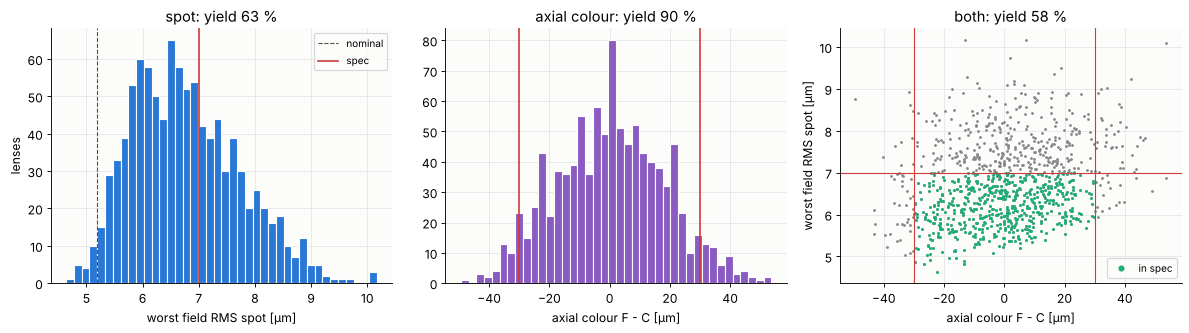

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ax = axes[0]
ax.hist(worst, bins=40, color=BLUE, edgecolor="white")
ax.axvline(nominal.max(), color="0.3", ls="--", lw=1, label="nominal")
ax.axvline(SPEC_SPOT, color=RED, lw=1.5, label="spec")
ax.set_xlabel("worst field RMS spot [µm]")
ax.set_ylabel("lenses")
ax.legend(fontsize=9)
ax.set_title(f"spot: yield {100*ok_spot.mean():.0f} %")
ax = axes[1]
ax.hist(col, bins=40, color="#8a5cc2", edgecolor="white")
for v in (-SPEC_COL, SPEC_COL):
    ax.axvline(v, color=RED, lw=1.5)
ax.set_xlabel("axial colour F - C [µm]")
ax.set_title(f"axial colour: yield {100*ok_col.mean():.0f} %")
ax = axes[2]
ax.plot(col, worst, ".", ms=3, color=GREY)
ax.plot(col[ok_spot & ok_col], worst[ok_spot & ok_col], ".", ms=3, color=GREEN, label="in spec")
ax.axhline(SPEC_SPOT, color=RED, lw=1)
for v in (-SPEC_COL, SPEC_COL):
    ax.axvline(v, color=RED, lw=1)
ax.set_xlabel("axial colour F - C [µm]")
ax.set_ylabel("worst field RMS spot [µm]")
ax.set_title(f"both: yield {100*(ok_spot & ok_col).mean():.0f} %")
ax.legend(fontsize=9, markerscale=3)
fig.tight_layout()

The distribution of the spot radius is skewed. The decentres add coma,
which adds to the nominal residual in quadrature, so the spot can only grow.
Hardly any lens is as good as the design, the median lens is about 25 %
worse, and more than a third of the lenses miss the 7 µm limit. The axial colour is
nearly Gaussian (a sum of small linear contributions) and independent of the
spot. One lens in ten has more colour than the depth of focus, and better
centring cannot fix that.

## 5. Axial positioning: fixed or adjusted focus

Section 4 assumed that the focus of every lens is adjusted. A cheaper
mechanical design has no adjustment: the doublet sits on a seat in the
barrel, and the detector on a flange. Then every axial error ends in the
focus: the axial position of the doublet in the barrel (±50 µm), the
position of the image plane (flange and detector, ±50 µm), the centre
thicknesses and the air gap. The radii, indices and Abbe numbers enter as
well, because they change the back focal length, which no longer gets
corrected.

In [8]:
fixed_tol = [t for t in tolerances if t.name != "z_img"] + \
    [tol.ImagePlane(0.05, after_compensation=False)]
best_focus = achromat.with_image_distance(achromat.surfaces[-1].thickness + model.c0[0])
ana_fixed = tol.ToleranceAnalysis(best_focus, fixed_tol, spot, (), metrics)
t0 = time.time()
z_img = fixed_tol[-1].sample(1000, np.random.default_rng(7))
mc_fixed = ana_fixed.monte_carlo(values=np.column_stack([mc.values[:, :-1], z_img]))  # same lenses
worst_fixed = mc_fixed.rms.max(1)*1e3
sens_fixed, model_fixed = ana_fixed.sensitivities()
print(f"{time.time() - t0:.0f} s; yield spot: adjusted focus {100*ok_spot.mean():.1f} %, "
      f"fixed focus {100*(worst_fixed <= SPEC_SPOT).mean():.1f} %")
print("largest shares of the spot variance with a fixed focus:")
for k in np.argsort(-sens_fixed.share)[:6]:
    print(f"  {sens_fixed.names[k]:8s} ±{sens_fixed.limits[k]:.4g}: {100*sens_fixed.share[k]:5.1f} %")

18 s; yield spot: adjusted focus 63.4 %, fixed focus 11.2 %
largest shares of the spot variance with a fixed focus:
  n1       ±0.0005:  34.9 %
  air gap  ±0.03:  27.6 %
  n3       ±0.0005:   8.2 %
  R1       ±3:   6.6 %
  R3       ±3:   5.8 %
  R2       ±3:   4.3 %


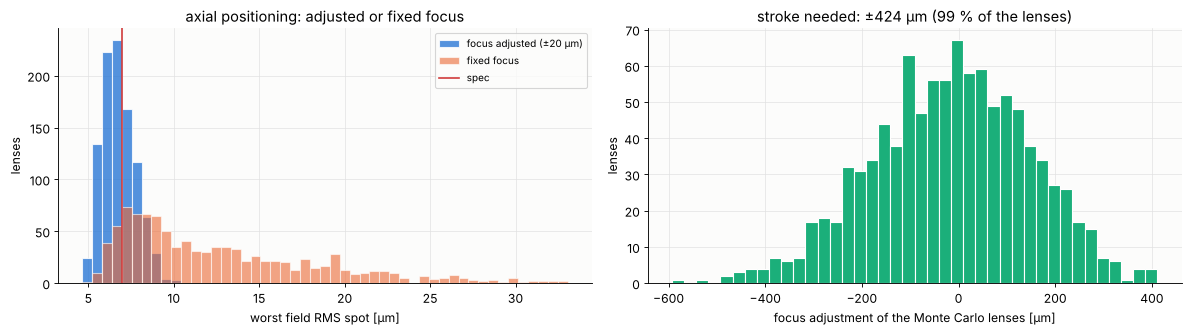

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
ax = axes[0]
bins = np.linspace(min(worst.min(), worst_fixed.min()), np.percentile(worst_fixed, 99.5), 50)
ax.hist(worst, bins=bins, color=BLUE, alpha=0.8, edgecolor="white", label="focus adjusted (±20 µm)")
ax.hist(worst_fixed, bins=bins, color=ORANGE, alpha=0.6, edgecolor="white", label="fixed focus")
ax.axvline(SPEC_SPOT, color=RED, lw=1.5, label="spec")
ax.set_xlabel("worst field RMS spot [µm]")
ax.set_ylabel("lenses")
ax.legend(fontsize=9)
ax.set_title("axial positioning: adjusted or fixed focus")
ax = axes[1]
ax.hist(1e3*mc.compensators[:, 0], bins=40, color=GREEN, edgecolor="white")
ax.set_xlabel("focus adjustment of the Monte Carlo lenses [µm]")
ax.set_ylabel("lenses")
ax.set_title(f"stroke needed: ±{1e3*np.percentile(np.abs(mc.compensators[:, 0]), 99):.0f} µm "
             "(99 % of the lenses)")
fig.tight_layout()

Without the adjustment the yield collapses. The defocus from the stacked
axial errors, a back focal length that scatters by some 160 µm (right
panel: the adjustment that section 4 needed), is several depths of focus.
In the fixed lens the budget is led by the index of the crown: ±5·10⁻⁴
changes its power by about 0.1 %, and since the crown carries 2.3 times
the power of the doublet, the focal length changes by about
100 mm · 2.3 · 0.001 ≈ 0.2 mm, many depths of focus. The air gap comes next,
then the radii, which also set the powers. The axial positions of the lens and
of the detector (±50 µm each) are only part of the defocus. The adjustment is cheap and removes all of this at once. The
budget then asks only for the accuracy of the focus setting, and for an
adjustment range of about ±0.4 mm.

## 6. The linear model against the full traces

The linear model is built from the same traces as the sensitivity table:
the performance vector $\mathbf y$ (here the weighted ray errors of all rays,
wavelengths and fields, about a thousand numbers), its Jacobian $J$ in the
17 errors from central differences at the limits, and the compensators
solved by linear least squares,
$\mathbf y = P(\mathbf y_0 + J\mathbf x)$ with $P = 1 - C C^+$. The merit
(block norms of $\mathbf y$) is computed exactly from the linear $\mathbf y$, so
it is quadratic in the errors: what the RSS estimate assumes, but with the
full distribution instead of the variance alone.

linear model: 201 000 lenses in 3.4 s
same lenses: largest difference of the worst field spot 46.0 nm, of the axial colour 0.377 um
yield (both specs): full traces 58.0 %, linear model on 200 000 lenses 56.98 %


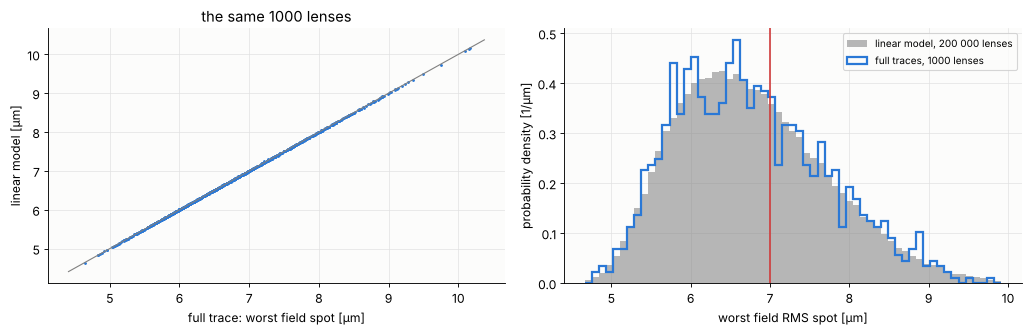

In [10]:
t0 = time.time()
lin_same = model.predict(mc.values)                 # the same 1000 lenses
lin_big = model.monte_carlo(200_000, seed=2)        # many more
t_lin = time.time() - t0
w_lin = lin_same.rms.max(1)*1e3
w_big = lin_big.rms.max(1)*1e3
print(f"linear model: 201 000 lenses in {t_lin:.1f} s")
print(f"same lenses: largest difference of the worst field spot {np.abs(w_lin - worst).max()*1e3:.1f} nm, "
      f"of the axial colour {np.abs(lin_same.metrics['axial colour'] - col).max():.3f} um")
print(f"yield (both specs): full traces {100*(ok_spot & ok_col).mean():.1f} %, "
      f"linear model on 200 000 lenses "
      f"{100*tol.yield_fraction(lin_big, SPEC_SPOT/1e3, {'axial colour': SPEC_COL}):.2f} %")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(worst, w_lin, ".", ms=3, color=BLUE)
lim = [worst.min()*0.95, worst.max()*1.02]
ax.plot(lim, lim, color="0.5", lw=1)
ax.set_xlabel("full trace: worst field spot [µm]")
ax.set_ylabel("linear model [µm]")
ax.set_title("the same 1000 lenses")
ax = axes[1]
bins = np.linspace(nominal.max()*0.9, np.percentile(w_big, 99.9), 60)
ax.hist(w_big, bins=bins, density=True, color=GREY, alpha=0.6, label="linear model, 200 000 lenses")
ax.hist(worst, bins=bins, density=True, histtype="step", lw=2, color=BLUE, label="full traces, 1000 lenses")
ax.axvline(SPEC_SPOT, color=RED, lw=1.5)
ax.set_xlabel("worst field RMS spot [µm]")
ax.set_ylabel("probability density [1/µm]")
ax.legend(fontsize=9)
fig.tight_layout()

For this lens the linear model is practically exact: the errors are small
against the scale on which the rays change non-linearly, so 36 trace
evaluations (two per tolerance and two for the compensator) replace the Monte Carlo
traces, and a hundred thousand lenses cost nothing. Monte Carlo with full
traces remains the reference, because it does not assume linearity, and
part 2 shows where the assumption starts to fail.

## 7. Tightening the budget, and the cemented doublet

With the linear model a tolerance budget can be tried in seconds. Changing a
limit only changes the distribution the errors are drawn from, while the
Jacobian per unit error stays. Two obvious upgrades: centring to ±10 µm (a
better mount, or centring on a lathe with the lens rotating) and the
tighter Abbe tolerance of a precision glass grade, ±0.3 % (or better, the
measured melt data and a re-optimization with them).

In [11]:
def yields_with(limits):
    saved = {t.name: t.limit for t in tolerances}
    for t in tolerances:
        for key, value in limits.items():
            if t.name.startswith(key):
                t.limit = value
    r = model.monte_carlo(100_000, seed=3)
    for t in tolerances:
        t.limit = saved[t.name]
    w = r.rms.max(1)*1e3
    return (100*(w <= SPEC_SPOT).mean(), 100*(np.abs(r.metrics["axial colour"]) <= SPEC_COL).mean(),
            100*tol.yield_fraction(r, SPEC_SPOT/1e3, {"axial colour": SPEC_COL}))


print(f"{'budget':42s} {'spot':>7s} {'colour':>7s} {'both':>7s}")
for label, limits in [("as in section 2", {}),
                      ("decentres ±10 µm", {"d": 0.01}),
                      ("Abbe ±0.3 %", {"V": 0.003}),
                      ("decentres ±10 µm and Abbe ±0.3 %", {"d": 0.01, "V": 0.003}),
                      ("... and air gap ±10 µm", {"d": 0.01, "V": 0.003, "air": 0.01})]:
    print(f"{label:42s}" + "".join(f"{v:7.1f}%" for v in yields_with(limits)))

budget                                        spot  colour    both


as in section 2                              62.8%   90.2%   57.1%


decentres ±10 µm                             96.9%   90.2%   87.9%


Abbe ±0.3 %                                  64.0%  100.0%   64.0%


decentres ±10 µm and Abbe ±0.3 %             97.9%  100.0%   97.9%


... and air gap ±10 µm                       98.3%  100.0%   98.3%


Centring buys the spot and the glass grade buys the colour. Each one alone
leaves the other merit as the limit. The air gap gains little once the
decentres are tight.

The other way out is a **less sensitive design**. A cemented doublet of the
same glasses has no air gap to despace and no inner surfaces that can be
shifted against each other: cementing aligns the two elements
(here with a residual decentre of ±5 µm between them, from the centring of
the cemented pair), and the pair is decentred as one element. With the three
curvatures, N-BK7/N-F2 cannot correct coma along with spherical aberration
(notebook 58), so its *nominal* spot at the edge of the field is worse.
The question is what is left after the tolerances.

In [12]:
cemented = design([rt.Surface(1/c1, 6.0, material=BK7, semi_diameter=SD),
                   rt.Surface(-1/c1, 3.0, material=F2, semi_diameter=SD),
                   rt.Surface(1/(-c1 - k2), 95.0, n_after=1.0, semi_diameter=SD)])
tol_cem = [tol.Power(i, 3.0, cemented.surfaces[i].semi_diameter) for i in range(3)]
tol_cem += [tol.Thickness(0, 0.05), tol.Thickness(1, 0.05), tol.AxialShift(0, 2, 0.05, name="lens z"),
            tol.Index(0, 5e-4), tol.Index(1, 5e-4),
            tol.Abbe(0, 0.008, relative=True), tol.Abbe(1, 0.008, relative=True),
            tol.Decenter(0, 2, 0.02, "x"), tol.Decenter(0, 2, 0.02, "y"),
            tol.Decenter(1, 2, 0.005, "x", name="cement dx"), tol.Decenter(1, 2, 0.005, "y", name="cement dy"),
            tol.ImagePlane(0.02)]
ana_cem = tol.ToleranceAnalysis(cemented, tol_cem, spot, focus, metrics)
nominal_cem = ana_cem.nominal_rms()*1e3
mc_cem = ana_cem.monte_carlo(1000, seed=4)
worst_cem = mc_cem.rms.max(1)*1e3
col_cem = mc_cem.metrics["axial colour"]
print(f"nominal worst field spot: air-spaced {nominal.max():.2f} um, cemented {nominal_cem.max():.2f} um")
for name, w, c in [("air-spaced", worst, col), ("cemented", worst_cem, col_cem)]:
    print(f"{name:10s}: median {np.median(w):.2f} um, 98 % {np.percentile(w, 98):.2f} um, "
          f"yield spot {100*(w <= SPEC_SPOT).mean():.1f} %, "
          f"both {100*((w <= SPEC_SPOT) & (np.abs(c) <= SPEC_COL)).mean():.1f} %")

nominal worst field spot: air-spaced 5.19 um, cemented 8.69 um
air-spaced: median 6.66 um, 98 % 8.91 um, yield spot 63.4 %, both 58.0 %
cemented  : median 8.74 um, 98 % 9.18 um, yield spot 0.0 %, both 0.0 %


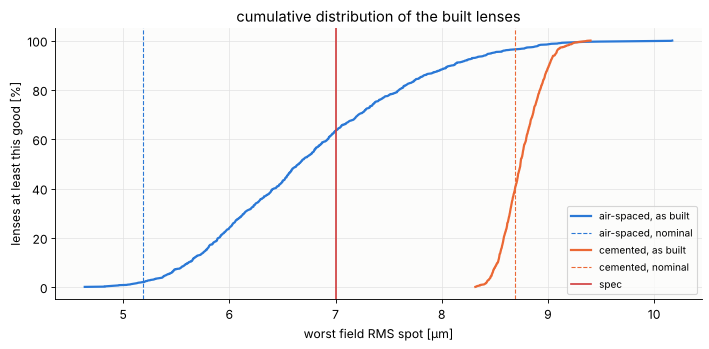

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, w, nom, c in [("air-spaced", worst, nominal.max(), BLUE), ("cemented", worst_cem, nominal_cem.max(), ORANGE)]:
    ws = np.sort(w)
    ax.plot(ws, 100*np.arange(1, len(ws) + 1)/len(ws), color=c, lw=2, label=f"{name}, as built")
    ax.axvline(nom, color=c, ls="--", lw=1, label=f"{name}, nominal")
ax.axvline(SPEC_SPOT, color=RED, lw=1.5, label="spec")
ax.set_xlabel("worst field RMS spot [µm]")
ax.set_ylabel("lenses at least this good [%]")
ax.set_title("cumulative distribution of the built lenses")
ax.legend(fontsize=9)
fig.tight_layout()

The cemented lens loses almost nothing to its tolerances: its curve rises
steeply around its nominal value, and 98 % of the lenses stay within
0.5 µm of it (a few are even slightly better, when the errors happen to
cancel some of the coma). The air-spaced lens loses most of its nominal
advantage. Its median is 1.5 µm worse than its design, and its worst lenses
end up next to the cemented ones. With the 7 µm specification only the
air-spaced form can pass at all, but at shop centring only two out of three
lenses do, and the budget of the table above is what it takes. With a 9 µm
specification the cemented doublet would be the safer and cheaper choice.
A tolerance-aware design chooses between the forms by the *as-built*
distribution, and desensitized design puts the sensitivities into the merit
function. The colour, set by the glasses, is the same for both.

## 8. Caldwell's KrF lens: sensitivities of 147 tolerances

Caldwell's all fused silica lens (`raytrace.caldwell_krf_lens()`, 21
elements, NA 0.56, 4x reduction, 248 nm) is a different scale of problem.
Notebook 44 showed that its correction is tense: Seidel terms of thousands
of waves cancel to a few hundredths, and 5 µm of decentre of a single element
near the stop costs 0.25 to 0.4 waves of coma. The merit is now the RMS
wavefront error (piston and tilt removed) at five field points, centre,
0.7, ±1 along y and 1 along x, on a 16 × 16 pupil grid
(`WavefrontErrors`).

The tolerances are those of a good optics shop, not of a lithography lens
maker, to see what they cost:

| tolerance | limit |
|---|---|
| power of each of the 42 surfaces | ±1 fringe |
| 21 centre thicknesses | ±10 µm |
| 20 air spaces | ±10 µm |
| index of each blank (homogeneity from blank to blank) | ±2·10⁻⁶ |
| decentre of each element, x and y | ±5 µm |
| wafer focus, after focusing | ±0.2 µm |

All elements are of the same glass, so there is no Abbe tolerance (the
monochromatic laser line makes it irrelevant anyway; the laser's bandwidth
is the colour tolerance of this lens, notebook 44). The compensator is the
wafer focus.

In [14]:
lens = rt.caldwell_krf_lens()
els = lens.elements()
SPEC_WF = 0.10   # waves RMS, worst field
tol_kr = tol.element_tolerances(lens, els, fringes=1.0, thickness=0.01, air=0.01, index=2e-6,
                                decenter=0.005)
tol_kr += [tol.ImagePlane(2e-4)]
wavefront = tol.WavefrontErrors(fields=(0.0, 0.7, 1.0, -1.0, (1.0, 0.0)), N=16)
t0 = time.time()
ana_kr = tol.ToleranceAnalysis(lens, tol_kr, wavefront, [lo.Thickness(-1)])
sens_kr, model_kr = ana_kr.sensitivities()
t_sens = time.time() - t0
nominal_kr = ana_kr.nominal_rms()
print(f"{len(tol_kr)} tolerances, {len(ana_kr.y0)} wavefront samples, sensitivities in {t_sens:.0f} s")
print("nominal RMS wavefront [waves]:", np.round(nominal_kr, 3))
print(f"RSS estimate (all fields): {np.sqrt(model_kr.mean_square()):.3f} waves")
groups = list(GROUP_COLOR)
share_group = {g: 100*sum(s for s, gg in zip(sens_kr.share, sens_kr.groups) if gg == g) for g in groups}
print("variance budget by group:", {g: round(v, 1) for g, v in share_group.items() if v > 0})

147 tolerances, 860 wavefront samples, sensitivities in 21 s
nominal RMS wavefront [waves]: [0.042 0.078 0.064 0.064 0.064]
RSS estimate (all fields): 0.155 waves
variance budget by group: {'radius': np.float64(1.2), 'thickness': np.float64(31.3), 'axial position': np.float64(1.4), 'index': np.float64(0.0), 'decenter': np.float64(66.0)}


elements with the largest share of the decentre budget: 14 (22 %), 21 (12 %), 16 (8 %), 15 (6 %), 8 (3 %), 7 (3 %)


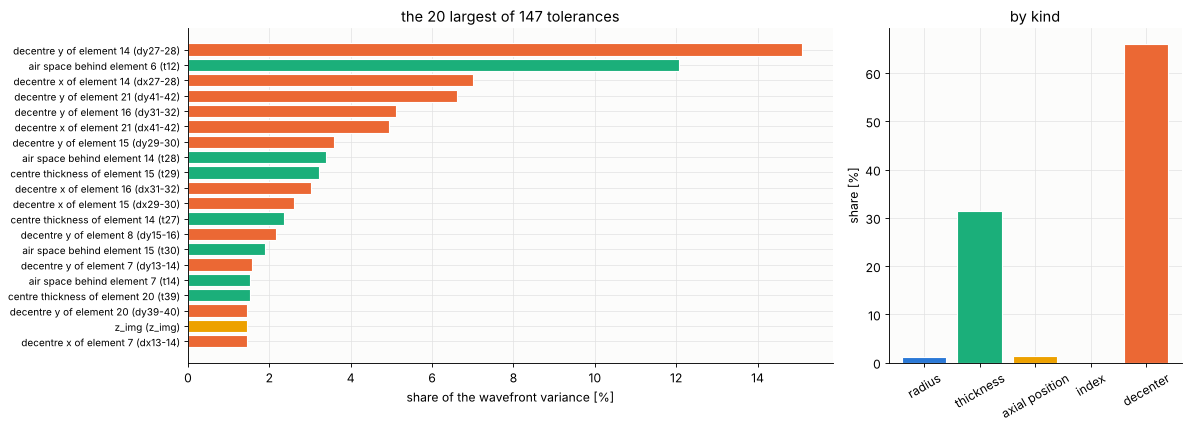

In [15]:
def element_of(surface):
    return next(k for k, (a, b) in enumerate(els) if a <= surface <= b) + 1


def describe(t):
    if isinstance(t, tol.Decenter):
        return f"decentre {t.axis} of element {element_of(t.first)}"
    if isinstance(t, tol.Thickness):
        s = t.surface
        if lens.n[s + 1] > 1.2:
            return f"centre thickness of element {element_of(s)}"
        return f"air space behind element {element_of(s)}"
    return t.name


order = np.argsort(-sens_kr.share)[:20]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
y = np.arange(len(order))[::-1]
ax.barh(y, 100*sens_kr.share[order], color=[GROUP_COLOR[sens_kr.groups[k]] for k in order],
        edgecolor="white")
ax.set_yticks(y, [f"{describe(tol_kr[k])} ({sens_kr.names[k]})" for k in order], fontsize=9)
ax.set_xlabel("share of the wavefront variance [%]")
ax.set_title("the 20 largest of 147 tolerances")
ax = axes[1]
gs = [g for g in groups if share_group[g] > 0]
ax.bar(range(len(gs)), [share_group[g] for g in gs], color=[GROUP_COLOR[g] for g in gs], edgecolor="white")
ax.set_xticks(range(len(gs)), gs, rotation=30)
ax.set_ylabel("share [%]")
ax.set_title("by kind")
fig.tight_layout()
dec_el = np.zeros(len(els))
for k, t in enumerate(tol_kr):
    if isinstance(t, tol.Decenter):
        dec_el[element_of(t.first) - 1] += sens_kr.share[k]
print("elements with the largest share of the decentre budget:",
      ", ".join(f"{k + 1} ({100*dec_el[k]:.0f} %)" for k in np.argsort(-dec_el)[:6]))

The decentres take about two thirds of the variance, and the air spaces and
centre thicknesses most of the rest. The elements that matter are the ones notebook 44 found
from the Seidel terms: the strong negative and positive lenses around the
second air lens and the stop (elements 14 to 16, and the last element in front
of the wafer), where the marginal ray is high and steep. One air space
stands out: the first air lens behind element 6 (surfaces 12/13), which
notebook 44 identified as a main source of the overcorrected spherical
aberration that balances the positive groups. A 10 µm change of its width
changes that balance.

The radii, toleranced in fringes, are harmless at ±1 fringe (much of the
radius error is defocus, which the focus removes), and the index of
fused silica blanks does not matter at the 10⁻⁶ level.

## 9. The linear model against full Monte Carlo runs, and where it breaks

A full Monte Carlo lens of Caldwell's design costs two traces of five
field points (perturbed and refocused), about 0.15 s, so 150 lenses take
under half a minute. The linear model used 2 × 147 traces for its Jacobian,
and then evaluates any number of lenses for free.

In [16]:
t0 = time.time()
mc_kr = ana_kr.monte_carlo(150, seed=5)
t_kr = time.time() - t0
lin_kr = model_kr.predict(mc_kr.values)
lin_kr_big = model_kr.monte_carlo(100_000, seed=6)
w_kr, w_kr_lin, w_kr_big = mc_kr.rms.max(1), lin_kr.rms.max(1), lin_kr_big.rms.max(1)
print(f"150 full lenses in {t_kr:.0f} s; largest difference to the linear model "
      f"{1e3*np.abs(w_kr - w_kr_lin).max():.1f} mλ")
print(f"yield at {SPEC_WF} waves: full {100*(w_kr <= SPEC_WF).mean():.0f} % (150 lenses), "
      f"linear {100*(w_kr_big <= SPEC_WF).mean():.1f} % (100 000 lenses)")

150 full lenses in 21 s; largest difference to the linear model 0.8 mλ
yield at 0.1 waves: full 3 % (150 lenses), linear 0.8 % (100 000 lenses)


At these tolerances the linear model reproduces every full trace to a
milliwave. The yield at 0.1 waves is low, though. Optics shop tolerances are not
good enough for this lens, which is why lithography lenses are centred to
a micrometre and adjusted (section 10).

Where does linearity end? The linear model leaves out the quadratic terms
of each error and the products of errors (two decentres, a decentre and a
despace). Relative to the linear terms they grow in proportion to the
errors, so scaling all tolerances by a common factor shows where they
start to matter.

tolerances x   1: median worst field wavefront full 0.200, linear 0.200 waves, median relative error 0.0 %


tolerances x   3: median worst field wavefront full 0.570, linear 0.568 waves, median relative error 0.1 %


tolerances x  10: median worst field wavefront full 1.895, linear 1.881 waves, median relative error 0.5 %


tolerances x  30: median worst field wavefront full 5.765, linear 5.638 waves, median relative error 1.4 %


tolerances x 100: median worst field wavefront full 20.158, linear 18.791 waves, median relative error 5.2 %


tolerances x 300: median worst field wavefront full 70.066, linear 56.369 waves, median relative error 15.6 %


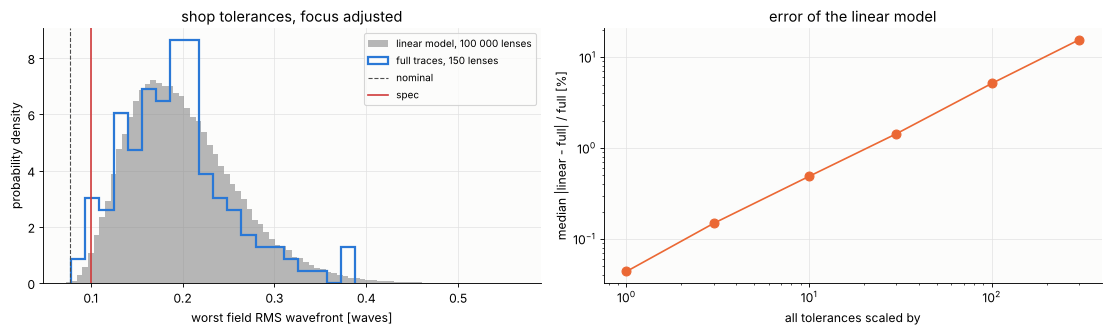

In [17]:
scales = [1.0, 3.0, 10.0, 30.0, 100.0, 300.0]
rel_err, med_full, med_lin = [], [], []
base = ana_kr.sample(25, seed=8)
for sc in scales:
    X = base*sc
    full = ana_kr.monte_carlo(values=X).rms.max(1)
    lin = model_kr.predict(X).rms.max(1)
    ok = np.isfinite(full)
    rel_err.append(np.median(np.abs(lin[ok] - full[ok])/full[ok]))
    med_full.append(np.median(full[ok]))
    med_lin.append(np.median(lin[ok]))
    print(f"tolerances x{sc:4.0f}: median worst field wavefront full {med_full[-1]:.3f}, "
          f"linear {med_lin[-1]:.3f} waves, median relative error {100*rel_err[-1]:.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
ax = axes[0]
ax.hist(w_kr_big, bins=80, density=True, color=GREY, alpha=0.6, label="linear model, 100 000 lenses")
ax.hist(w_kr, bins=20, density=True, histtype="step", lw=2, color=BLUE, label="full traces, 150 lenses")
ax.axvline(nominal_kr.max(), color="0.3", ls="--", lw=1, label="nominal")
ax.axvline(SPEC_WF, color=RED, lw=1.5, label="spec")
ax.set_xlabel("worst field RMS wavefront [waves]")
ax.set_ylabel("probability density")
ax.legend(fontsize=9)
ax.set_title("shop tolerances, focus adjusted")
ax = axes[1]
ax.loglog(scales, 100*np.array(rel_err), "o-", color=ORANGE, ms=8)
ax.set_xlabel("all tolerances scaled by")
ax.set_ylabel("median |linear - full| / full [%]")
ax.set_title("error of the linear model")
fig.tight_layout()

The error of the linear model grows in proportion to the scale, as
expected for neglected second order terms. It is a few hundredths of a percent at the shop
tolerances and about 1 % at thirty times (150 µm decentres, 0.3 mm
air spaces, wavefront errors of several waves). Only at a hundred times and
more, millimetre errors and tens of waves, does it reach 5 to 20 %, where nobody
would tolerance a lens anyway. The wavefront of this tense
lens responds very linearly to its errors. Its sensitivity comes from the size of
the linear coefficients, not from non-linearity. That is why the linear
model makes tolerancing a lens with hundreds of parameters, and choosing
its compensators, possible at all. A few full Monte Carlo runs check it,
as here.

## 10. Manipulators: what adjustable elements win back

Lithography lenses are not built to the budget of section 8 and then
accepted. They are measured interferometrically and adjusted: some elements
sit in mounts that move them along the axis (**axial manipulators**, which
change two air spaces at once, `lo.AirSpace`) or across it (**lateral
manipulators**, `tol.LateralShift`, which can cancel the coma of a decentred
element with the coma of another). Which elements should be adjustable?

The linear model answers this without new traces of the tolerances. Each
candidate needs only its own column, its effect on the wavefront. Greedy
selection: add the manipulator (an axial one, or a lateral one in x and y)
that lowers the expected mean square of the compensated wavefront most,
then the next.

In [18]:
cands, cgroups = [], []
for k, (a, b) in enumerate(els):
    if a > 0:
        cgroups.append(([len(cands)], f"axial {k + 1}"))
        cands.append(lo.AirSpace(a, b))
    cgroups.append(([len(cands), len(cands) + 1], f"lateral {k + 1}"))
    cands += [tol.LateralShift(a, b, "x"), tol.LateralShift(a, b, "y")]
t0 = time.time()
C_cand, G_cand = ana_kr.compensator_jacobian(cands)
print(f"{len(cgroups)} candidate manipulators, columns traced in {time.time() - t0:.0f} s")


def rss(chosen):
    cols = [i for g in chosen for i in cgroups[g][0]]
    m = model_kr.with_compensators([lo.Thickness(-1)] + [cands[i] for i in cols],
                                   np.column_stack([ana_kr.C, C_cand[:, cols]]),
                                   np.zeros((0, 1 + len(cols))))
    return np.sqrt(m.mean_square()), m


chosen, curve = [], [rss([])[0]]
for _ in range(8):
    best = min((g for g in range(len(cgroups)) if g not in chosen), key=lambda g: rss(chosen + [g])[0])
    chosen.append(best)
    curve.append(rss(chosen)[0])
    print(f"+ {cgroups[best][1]:12s} RSS wavefront {curve[-1]:.3f} waves")

41 candidate manipulators, columns traced in 9 s
+ lateral 8    RSS wavefront 0.119 waves
+ axial 12     RSS wavefront 0.098 waves


+ lateral 18   RSS wavefront 0.083 waves
+ axial 19     RSS wavefront 0.072 waves
+ lateral 7    RSS wavefront 0.066 waves


+ axial 14     RSS wavefront 0.061 waves
+ axial 2      RSS wavefront 0.054 waves
+ axial 21     RSS wavefront 0.053 waves


In [19]:
N_MAN = 5
cols = [i for g in chosen[:N_MAN] for i in cgroups[g][0]]
manip = [lo.Thickness(-1)] + [cands[i] for i in cols]
ana_man = ana_kr.with_compensators(manip, np.column_stack([ana_kr.C, C_cand[:, cols]]),
                                   np.zeros((0, len(manip))), iterations=2)
model_man = tol.LinearModel(ana_man, model_kr.J, model_kr.G)
t0 = time.time()
mc_man = ana_man.monte_carlo(values=mc_kr.values[:100])
t_man = time.time() - t0
w_man = mc_man.rms.max(1)
w_man_lin = model_man.predict(mc_kr.values[:100]).rms.max(1)
w_man_big = model_man.monte_carlo(100_000, seed=6).rms.max(1)
print(f"100 full lenses with {N_MAN} manipulators in {t_man:.0f} s, "
      f"largest difference to the linear model {1e3*np.abs(w_man - w_man_lin).max():.1f} mλ")
print(f"yield at {SPEC_WF} waves: focus only {100*(w_kr_big <= SPEC_WF).mean():.1f} %, "
      f"with {N_MAN} manipulators {100*(w_man_big <= SPEC_WF).mean():.1f} % (linear, 100 000 lenses), "
      f"{100*(w_man <= SPEC_WF).mean():.0f} % (full, 100 lenses)")
strokes = 1e3*np.abs(mc_man.compensators[:, 1:])
print("manipulator strokes (99th percentile, um):",
      ", ".join(f"{m.name}: {s:.0f}" for m, s in zip(manip[1:], np.percentile(strokes, 99, axis=0))))

100 full lenses with 5 manipulators in 20 s, largest difference to the linear model 0.0 mλ
yield at 0.1 waves: focus only 0.8 %, with 5 manipulators 99.2 % (linear, 100 000 lenses), 100 % (full, 100 lenses)
manipulator strokes (99th percentile, um): lateral x15-16: 21, lateral y15-16: 23, shift22-23: 97, lateral x35-36: 25, lateral y35-36: 23, shift36-37: 135, lateral x13-14: 14, lateral y13-14: 18


total run time 206 s


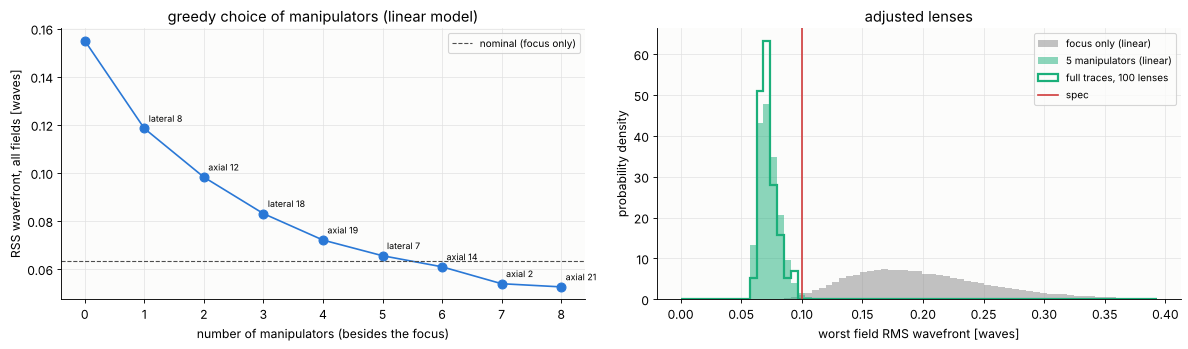

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ax = axes[0]
ax.plot(range(len(curve)), curve, "o-", color=BLUE, ms=8)
ax.axhline(np.sqrt(np.mean(nominal_kr**2)), color="0.3", ls="--", lw=1, label="nominal (focus only)")
for k, g in enumerate(chosen):
    ax.annotate(cgroups[g][1], (k + 1, curve[k + 1]), textcoords="offset points", xytext=(4, 6), fontsize=8)
ax.set_xlabel("number of manipulators (besides the focus)")
ax.set_ylabel("RSS wavefront, all fields [waves]")
ax.set_title("greedy choice of manipulators (linear model)")
ax.legend(fontsize=9)
ax = axes[1]
bins = np.linspace(0, np.percentile(w_kr_big, 99.5), 70)
ax.hist(w_kr_big, bins=bins, density=True, color=GREY, alpha=0.5, label="focus only (linear)")
ax.hist(w_man_big, bins=bins, density=True, color=GREEN, alpha=0.5, label=f"{N_MAN} manipulators (linear)")
ax.hist(w_man, bins=bins, density=True, histtype="step", lw=2, color=GREEN, label="full traces, 100 lenses")
ax.axvline(SPEC_WF, color=RED, lw=1.5, label="spec")
ax.set_xlabel("worst field RMS wavefront [waves]")
ax.set_ylabel("probability density")
ax.legend(fontsize=9)
ax.set_title("adjusted lenses")
fig.tight_layout()
print(f"total run time {time.time() - t_start:.0f} s")

Five manipulators, chosen by the linear model and checked with full traces
(Gauss-Newton with the nominal Jacobian of the manipulators, two steps),
lower the RSS wavefront from 0.155 to 0.066 waves and raise the yield at
0.1 waves from about 1 % to 99 %. The full traces agree with the linear
model again. The RSS even falls below the nominal design. The manipulators
also remove part of the design residual, which is a re-optimization of the
nominal lens with five more variables. The choice is not simply the most
sensitive elements (14 and 21). A manipulator is useful when its effect on
the wavefront over the field resembles what the errors do. Lateral
manipulators (elements 7, 8 and 18) produce field-dependent coma and
astigmatism like the decentres, and axial ones (elements 12 and 19) rebalance the
spherical aberration and field curvature that the air space errors leave.
The strokes needed are about 25 µm laterally and 0.1 mm axially. The rest of the way to a production lens is tighter
tolerances (centring to a micrometre, air spaces measured and ground to
size during assembly) and, after the interferometric test, the correction
of the residual, e.g. by aspherized correction plates.

## Summary

- `pyoptics.tolerancing` describes the errors of a lens as `Tolerance`
  objects (`Power`, `Radius`, `Thickness`, `AxialShift`, `ImagePlane`, `Index`,
  `Abbe`, `Decenter`, with Gaussian, uniform or end point distributions),
  the performance as a vector whose blocks give the RMS spot (`SpotErrors`)
  or the RMS wavefront (`WavefrontErrors`) per field, and compensators as
  optimizer variables (`lens_optimization.Thickness(-1)` for the focus,
  `AirSpace` for axial and `tolerancing.LateralShift` for lateral
  manipulators). `ToleranceAnalysis` gives the sensitivity table, full
  Monte Carlo runs and the linear model, which also chooses compensators
  (`compensator_jacobian()`, `with_compensators()`).
- **Air-spaced achromat:** the spot is limited by the centring of the two
  elements (the steep inner surfaces across the air gap), the axial colour by
  the Abbe number tolerance of the glasses (±0.8 % is a full depth of focus).
  The axial positions (lens in the barrel, detector) are harmless when the
  focus is adjusted. When it is not, the stacked focus errors (led by the
  index of the crown) ruin the lens. The cemented doublet is nominally worse
  but hardly sensitive at all. The air-spaced doublet loses most of its advantage
  unless it is centred to ±10 µm.
- **Caldwell's KrF lens:** at optics shop tolerances, decentres of the
  elements around the second waist and the stop and the width of the first
  air lens dominate. The linear model matches full Monte Carlo traces to a
  milliwave and stays within about 1 % up to thirty times these
  tolerances. Five manipulators chosen with it lower the RSS wavefront error of
  the built lenses from 0.155 to 0.066 waves.

Exercises: tolerance the Cooke triplet of notebook 58 (its air spaces are
its most sensitive parameters); add tilts of the elements; use uniform
or end point distributions and compare the yields; put the decentre
sensitivities into the merit function of the achromat design and trade
nominal against as-built performance.

## References

- W. J. Smith, *Modern Optical Engineering*, 4th ed., McGraw-Hill (2008) (tolerances, statistics and compensators).
- R. R. Shannon, *The Art and Science of Optical Design*, Cambridge University Press (1997) (tolerancing).
- H. H. Hopkins and H. J. Tiziani, "A theoretical and experimental study of lens centring errors and their influence on optical image quality", Br. J. Appl. Phys. 17, 33-54 (1966).
- J. B. Caldwell, "All-fused-silica 248-nm lithographic projection lens", Optics & Photonics News 9(11), 40-41 (1998).
- R. Kingslake and R. B. Johnson, *Lens Design Fundamentals*, 2nd ed., Academic Press (2010) (achromats, air-spaced and cemented).
- Schott AG, *Optical Glass - Data Sheets* (nominal n_d, V_d and their tolerance grades).